_Aprendizaje Automático_

_AI Engineering Portfolio_

# Laboratorio: Regresión lineal y árboles de decisión para tareas de regresión


## Objetivos

Mediante esta actividad se pretende que ponga en práctica los pasos para la resolución de un problema de machine learning, el tratamiento de datos y la creación de modelos basados en regresión lineal y árboles de decisión. El objetivo es comprender de forma práctica con un problema determinado las diferencias que existen a la hora de entrenar los diferentes modelos.

- Iniciarse en el Análisis Exploratorio de Datos (EDA) para los problemas de Machine Learning.
- Entender y aplicar los conceptos de la Regresión Lineal Múltiple a un problema de regresión.
- Entender y aplicar los conceptos de Árboles de Decisión a un problema de regresión.
- Evaluar y analizar los resultados de los clasificadores.
- Investigar la aplicación de los modelos de clasificación a problemas reales.


## Descripción de la actividad

Debes completar los espacios indicados en el notebook con el código solicitado y la respuesta, en función de lo que se solicite. Ten encuenta que las celdas vacías indican cuántas líneas debe ocupar la respuesta, por lo general no más de una línea.

El conjunto de datos con el que vamos a trabajar se encuentra en el siguiente enlace: https://archive.ics.uci.edu/dataset/360/air+quality

Se trata de un dataset con un conjunto de datos sobre calidad del aire. El conjunto de datos contiene 9358 instancias de respuestas promediadas por hora de una matriz de 5 sensores químicos de óxido de metal integrados en un dispositivo multisensor químico de calidad del aire. El dispositivo estaba ubicado en un área significativamente contaminada, al nivel de la carretera, dentro de una ciudad italiana. Los datos se registraron desde marzo de 2004 hasta febrero de 2005 (un año).

El objetivo de la regresión será predecir la calidad del aire para un determinado día.

### Tareas que se deben realizar

- Análisis descriptivo de los datos:
   - Debe completarse el código solicitado y responder a las preguntas. Todo ello en el notebook dado como base.
- Regresión:
  - Debe completarse el código solicitado y responder a las preguntas. Todo ello en el notebook dado como base.
- Investigación:
  - Buscar un artículo científico (https://scholar.google.es/) con un caso de uso de regresión empleando una de las dos técnicas (o ambas) vistas en la actividad. Los artículos deben estar en revistas científicas, y deben ser posteriores a 2015. No debe utilizar técnicas de Deep Learning.
  - Para el artículo indicar:
    - Objetivo: cuál es el objetivo de la investigación, es decir a qué problema real está aplicando la regresión.
    - Cómo utilizan las técnicas de regresión, si realizan alguna adaptación de los algoritmos indicarse.
    - Principales resultados de la aplicación y de la investigación.


### Análisis descriptivo de los datos
A continuación vas a encontrar una serie de preguntas que tendrás que responder. Para responder tendrás que escribir (y ejecutar) una (o más de una) línea de código, y a continuación indicar la respuesta en la celda indicada.

In [1]:
## cargar el dataset

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

# Especificamos el separador y el decimal
df = pd.read_csv('AirQualityUCI.csv', sep=';', decimal=',')

# Eliminamso las dos últimas columnas ya que estan vacias.
df = df.dropna(how='all', axis=1) 
df = df.dropna(how='all', axis=0)

# Reemplazar el valor -200 por NaN
df.replace(-200, np.nan, inplace=True)

df.head()

,Date,Time,CO(GT),PT08.S1(CO),NMHC(GT),C6H6(GT),PT08.S2(NMHC),NOx(GT),PT08.S3(NOx),NO2(GT),PT08.S4(NO2),PT08.S5(O3),T,RH,AH
0,10/03/2004,18.00.00,2.6,1360.0,150.0,11.9,1046.0,166.0,1056.0,113.0,1692.0,1268.0,13.6,48.9,0.7578
1,10/03/2004,19.00.00,2.0,1292.0,112.0,9.4,955.0,103.0,1174.0,92.0,1559.0,972.0,13.3,47.7,0.7255
2,10/03/2004,20.00.00,2.2,1402.0,88.0,9.0,939.0,131.0,1140.0,114.0,1555.0,1074.0,11.9,54.0,0.7502
3,10/03/2004,21.00.00,2.2,1376.0,80.0,9.2,948.0,172.0,1092.0,122.0,1584.0,1203.0,11.0,60.0,0.7867
4,10/03/2004,22.00.00,1.6,1272.0,51.0,6.5,836.0,131.0,1205.0,116.0,1490.0,1110.0,11.2,59.6,0.7888


In [3]:
## ¿cuántas instancias tiene el dataset?

In [4]:
print(f"Instancias (filas): {df.shape[0]}")

Instancias (filas): 9357


In [5]:
## ¿cuál es el tipo de datos de cada una de las columnas?

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9357 entries, 0 to 9356
Data columns (total 15 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Date           9357 non-null   object 
 1   Time           9357 non-null   object 
 2   CO(GT)         7674 non-null   float64
 3   PT08.S1(CO)    8991 non-null   float64
 4   NMHC(GT)       914 non-null    float64
 5   C6H6(GT)       8991 non-null   float64
 6   PT08.S2(NMHC)  8991 non-null   float64
 7   NOx(GT)        7718 non-null   float64
 8   PT08.S3(NOx)   8991 non-null   float64
 9   NO2(GT)        7715 non-null   float64
 10  PT08.S4(NO2)   8991 non-null   float64
 11  PT08.S5(O3)    8991 non-null   float64
 12  T              8991 non-null   float64
 13  RH             8991 non-null   float64
 14  AH             8991 non-null   float64
dtypes: float64(13), object(2)
memory usage: 1.1+ MB


In [7]:
## ¿cuántas columnas categóricas hay? ¿y cuántas continuas?

Hay 13 columnas de tipo float64 (continuas). Date y Time son objetos (o categóricas si no se parsean).

In [8]:
## ¿existen valores nulos en el dataset?

In [9]:
df.isnull().sum()

Date                0
Time                0
CO(GT)           1683
PT08.S1(CO)       366
NMHC(GT)         8443
C6H6(GT)          366
PT08.S2(NMHC)     366
NOx(GT)          1639
PT08.S3(NOx)      366
NO2(GT)          1642
PT08.S4(NO2)      366
PT08.S5(O3)       366
T                 366
RH                366
AH                366
dtype: int64

In [10]:
## ¿cuál es la variable respuesta?¿de qué tipo es?

La variable de respuesta es C6H6(GT), que corresponde a la concentración media horaria real de benceno en el aire. Esta medición se obtiene a partir de un analizador de referencia certificado (Ground Truth), lo que la convierte en un valor fiable para el entrenamiento del modelo.

Se trata de una variable cuantitativa continua, expresada en microgramos por metro cúbico ($\mu g/m^3$).

In [11]:
## Si te fijas en los estadísticos del dataset, ¿cómo es la distribución de las variables, CO, NOx y NO2? 

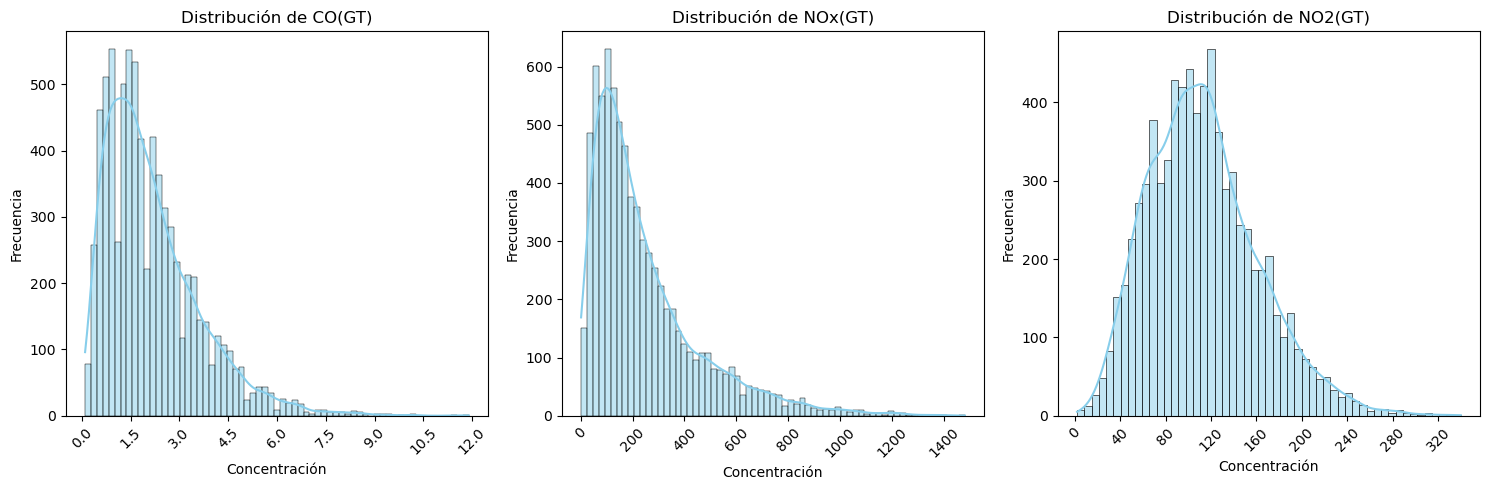

In [12]:
cols_analisis = ['CO(GT)', 'NOx(GT)', 'NO2(GT)']

plt.figure(figsize=(15, 5))

for i, col in enumerate(cols_analisis):
    # Creamos el subplot y guardamos la referencia "ax" para modificarlo
    ax = plt.subplot(1, 3, i+1)
    
    # Dibujamos el histograma
    sns.histplot(df[col].dropna(), kde=True, color='skyblue')
    
    plt.title(f'Distribución de {col}')
    plt.xlabel('Concentración')
    plt.ylabel('Frecuencia')
    
    # --- SOLUCIÓN VISUAL ---
    # 1. Rotamos los números 45 grados para que no se pisen
    plt.xticks(rotation=45)
    
    # 2. Forzamos a que no haya más de 10 etiquetas en el eje X
    ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=10))

plt.tight_layout()
plt.show()

¿Estas variables muestran alguna distribución especial?¿Tienen datos faltantes?¿y datos anómalos?

In [13]:
df[['CO(GT)', 'NOx(GT)', 'NO2(GT)']].describe()

,CO(GT),NOx(GT),NO2(GT)
count,7674.000000,7718.000000,7715.000000
mean,2.152750,246.896735,113.091251
std,1.453252,212.979168,48.370108
min,0.100000,2.000000,2.000000
25%,1.100000,98.000000,78.000000
50%,1.800000,180.000000,109.000000
75%,2.900000,326.000000,142.000000
max,11.900000,1479.000000,340.000000


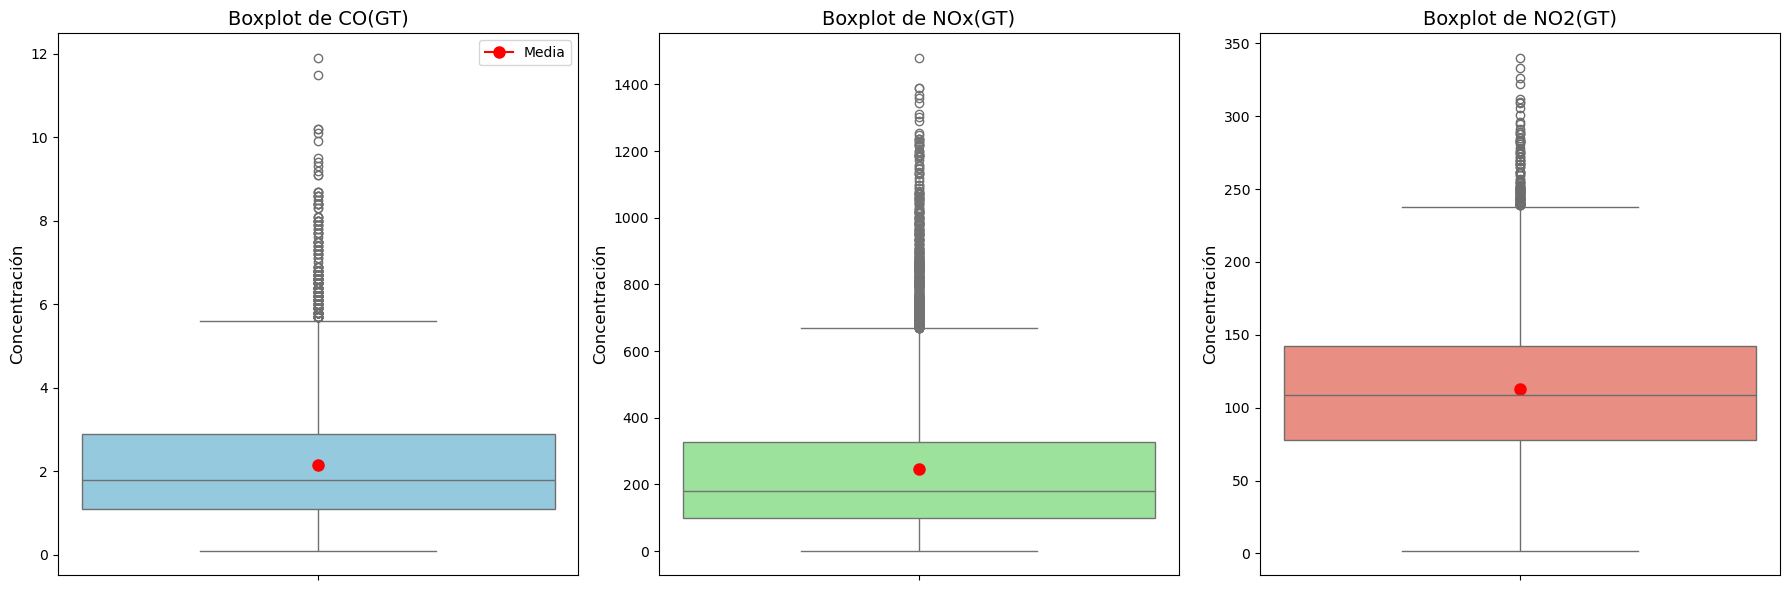

In [14]:
# Seleccionamos las variables
vars_caja = ['CO(GT)', 'NOx(GT)', 'NO2(GT)']
colores = ['skyblue', 'lightgreen', 'salmon']

# Creamos una figura con 3 subgráficos uno al lado del otro
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for i, col in enumerate(vars_caja):
    # Dibujamos el boxplot
    sns.boxplot(y=df[col].dropna(), ax=axes[i], color=colores[i])
    
    # Títulos y etiquetas para que quede profesional
    axes[i].set_title(f'Boxplot de {col}', fontsize=14)
    axes[i].set_ylabel('Concentración', fontsize=12)
    
    # Opcional: mostrar la media como un punto rojo para comparar con la mediana
    media = df[col].mean()
    axes[i].plot(0, media, marker='o', color='red', markersize=8, label='Media')
    if i == 0: axes[i].legend() # Solo poner leyenda en el primero

plt.tight_layout()
plt.show()

In [15]:
# Seleccionamos tus variables de interés
variables = ['CO(GT)', 'NOx(GT)', 'NO2(GT)']

for col in variables:
    # 1. Calcular Cuartiles y RIC (Rango Intercuartílico)
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    RIC = Q3 - Q1
    
    # 2. Definir los Límites Superiores (En contaminación nos preocupa lo alto)
    # Nota: No calculamos límite inferior porque la contaminación no baja de 0.
    limite_atipico = Q3 + 1.5 * RIC
    limite_extremo = Q3 + 3.0 * RIC
    
    # 3. Filtrar los datos para contarlos
    # Atípicos totales (incluye leves y extremos)
    total_atipicos = df[df[col] > limite_atipico]
    
    # Extremos (solo los muy altos)
    solo_extremos = df[df[col] > limite_extremo]
    
    # 4. Imprimir Reporte
    print(f"--- ANÁLISIS DE: {col} ---")
    print(f"RIC (Rango Intercuartílico): {RIC:.2f}")
    print(f"Límite Atípico (1.5x): > {limite_atipico:.2f}")
    print(f"Límite Extremo (3.0x): > {limite_extremo:.2f}")
    print(f"--> Cantidad de valores Atípicos: {len(total_atipicos)} ({(len(total_atipicos)/len(df))*100:.2f}%)")
    print(f"--> Cantidad de valores EXTREMOS: {len(solo_extremos)} ({(len(solo_extremos)/len(df))*100:.2f}%)")
    print("-" * 30 + "\n")

--- ANÁLISIS DE: CO(GT) ---
RIC (Rango Intercuartílico): 1.80
Límite Atípico (1.5x): > 5.60
Límite Extremo (3.0x): > 8.30
--> Cantidad de valores Atípicos: 215 (2.30%)
--> Cantidad de valores EXTREMOS: 27 (0.29%)
------------------------------

--- ANÁLISIS DE: NOx(GT) ---
RIC (Rango Intercuartílico): 228.00
Límite Atípico (1.5x): > 668.00
Límite Extremo (3.0x): > 1010.00
--> Cantidad de valores Atípicos: 435 (4.65%)
--> Cantidad de valores EXTREMOS: 75 (0.80%)
------------------------------

--- ANÁLISIS DE: NO2(GT) ---
RIC (Rango Intercuartílico): 64.00
Límite Atípico (1.5x): > 238.00
Límite Extremo (3.0x): > 334.00
--> Cantidad de valores Atípicos: 107 (1.14%)
--> Cantidad de valores EXTREMOS: 1 (0.01%)
------------------------------



**1. Distribución y Tendencia Central**
Observamos una distribución con **asimetría positiva**, caracterizada por una cola derecha extensa (distribución log-normal).

**2. Integridad de los Datos**
Respecto a la integridad de los datos, las variables presentan un conteo válido de entre **7.674 y 7.718 registros**, lo que implica una tasa de datos faltantes cercana al **18%** tras la depuración de códigos de error (`-200`).

**3. Análisis de Valores Atípicos (Outliers)**
Se detectaron anomalías mediante el criterio del **Rango Intercuartílico (RIC)**, distinguiendo entre valores atípicos ($>1.5 \times RIC$) y extremos ($>3 \times RIC$). Los resultados confirman que estos datos corresponden a **episodios reales puntuales de alta contaminación** y no a errores de medición.

In [16]:
## ¿cómo son las correlaciones entre las variables del dataset?

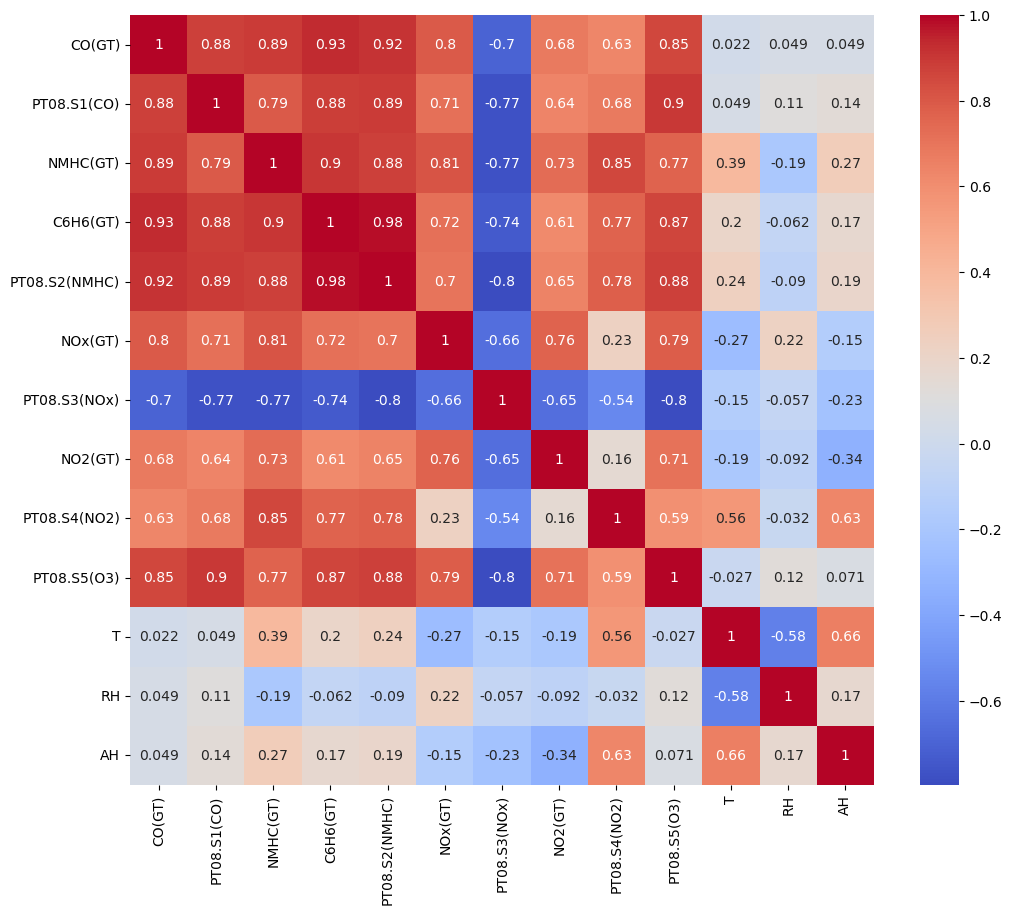

In [17]:
plt.figure(figsize=(12, 10))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm')
plt.show()

* Alta correlación positiva entre contaminantes: Existe una fuerte relación lineal entre las variables de los sensores químicos y las concentraciones de contaminantes. Destaca especialmente la correlación casi perfecta de 0.98 entre C6H6(GT) (Benceno) y el sensor PT08.S2(NMHC), así como la de 0.93 entre CO(GT) y C6H6(GT). Esto indica que estos sensores capturan información muy similar y presentan una alta multicolinealidad.

* Correlación inversa del sensor S3: La variable PT08.S3(NOx) muestra correlaciones negativas fuertes con la mayoría de los otros contaminantes (ej. -0.80 con PT08.S2 y -0.74 con C6H6). Esto sugiere una relación inversamente proporcional: a mayor presencia de óxidos de nitrógeno u otros compuestos, menor es la lectura de este sensor (típico en sensores de óxido metálico donde la resistencia disminuye al aumentar el gas).

* Baja correlación de variables meteorológicas: Las variables climáticas (T, RH, AH) presentan, en general, correlaciones mucho más débiles con los contaminantes en comparación con la relación entre los propios sensores químicos. Por ejemplo, la Humedad Relativa (RH) tiene coeficientes cercanos a 0 con varios contaminantes, lo que indica que no es un predictor lineal fuerte por sí solo para la calidad del aire en este dataset.

In [18]:
## ¿qué tres variables son las más correlacionadas con la variable objetivo?

Si consideramos C6H6(GT) como la variable objetivo, las tres variables más correlacionadas son:

1. PT08.S2(NMHC): Con un coeficiente de correlación de 0.98. Esta es la correlación más fuerte del dataset, indicando una relación lineal casi perfecta.

2. CO(GT): Con un coeficiente de 0.93. Muestra una relación muy fuerte, lo que tiene sentido ya que el monóxido de carbono y el benceno suelen provenir de las mismas fuentes de combustión (tráfico).

3. NMHC(GT): Con un coeficiente de 0.90. (Nota: Si esta variable tiene muchos nulos en tu limpieza de datos, la siguiente opción sería PT08.S1(CO) con 0.88).

In [19]:
## ¿existe alguna variable que no tenga correlación?

No existe ninguna variable que tenga una correlación de 0 absoluto (ausencia total de relación matemática) con todas las demás, pero las variables meteorológicas, especialmente RH (Humedad Relativa) y T (Temperatura), presentan correlaciones despreciables (muy cercanas a 0) con varios de los contaminantes.

In [20]:
## En base al EDA realizado, ¿qué suposiciones se pueden hacer sobre los datos?¿qué conclusiones extraes para implementar el modelo predictivo?

1. Necesidad de Escalado: Dado que los sensores tienen rangos de valores muy distintos (unos en cientos, otros en miles), es imprescindible escalar o normalizar los datos para que la Regresión Lineal funcione correctamente y los coeficientes sean comparables.

2. Selección de Variables: Para la Regresión Lineal, es recomendable no usar todas las variables a la vez para evitar problemas de multicolinealidad e inestabilidad en los coeficientes.

3. Limpieza de Ruido: La eliminación de los valores -200 (nulos) es crítica antes del entrenamiento para no sesgar el modelo.

### Regresión

Para llevar a cabo la tarea de regresión deseada se pretender hacer una comparativa de varios modelos. Unos usarán el algortimo de regresión lineal, y otros realizarán la predicción haciendo uso de árboles de decisión.

Para los primeros modelos hay que usar el módulo https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html 

El algortimo de Regresión Lineal necesita saber cuáles son las variables que va a tener en cuenta para realizar la estimación.

El primero modelo que se debe construir usará una regresión lineal simple. Para ello sigue los siguientes pasos.

Antes de empezar con la implementación de los modelos hace falta realizar una transformación de datos, escalarlos.

In [21]:
# Preparación de datos (Eliminamos NaNs para poder entrenar)
df_clean = df.dropna()

# Definir X e y
target = 'C6H6(GT)'
X = df_clean.drop(columns=['Date', 'Time', target]) # Quitamos fecha, hora y el objetivo
y = df_clean[target]

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Escalado
scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)

# Separar train y test
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2, random_state=42) #fijamos semilla para reproducibilidad

# Entrenar Regresión Lineal Simple
best_feature = 'PT08.S2(NMHC)'
X_train_simple = X_train[[best_feature]]
X_test_simple = X_test[[best_feature]]

model_simple = LinearRegression()
model_simple.fit(X_train_simple, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [22]:
# ¿cuáles son los valores aprendidos por el modelo para los parámetros?

In [23]:
print("Coeficiente (pendiente):", model_simple.coef_)
print("Intercepto:", model_simple.intercept_)

Coeficiente (pendiente): [7.25438677]
Intercepto: 10.758276824501225


Explica qué indican estos parámetros

La regresión lineal sigue la ecuación $y = w_0 + w_1 \cdot x$. Los parámetros aprendidos indican lo siguiente:
* Intercepto ($10.76$): Es el valor base de la predicción. Indica que, cuando la variable predictora (el sensor) tiene un valor de 0 (que, al estar los datos escalados con StandardScaler, corresponde a la media del sensor), la concentración esperada de C6H6 es de 10.76.
* Coeficiente ($7.25$): Es la pendiente de la recta. Indica cuánto aumenta la variable objetivo por cada unidad que aumenta la variable predictora. Dado que los datos de entrada ($X$) están escalados, esto significa que por cada aumento de 1 desviación estándar en la lectura del sensor, la concentración de C6H6 aumenta en 7.25 unidades.

NameError: name 'y_pred_simple' is not defined

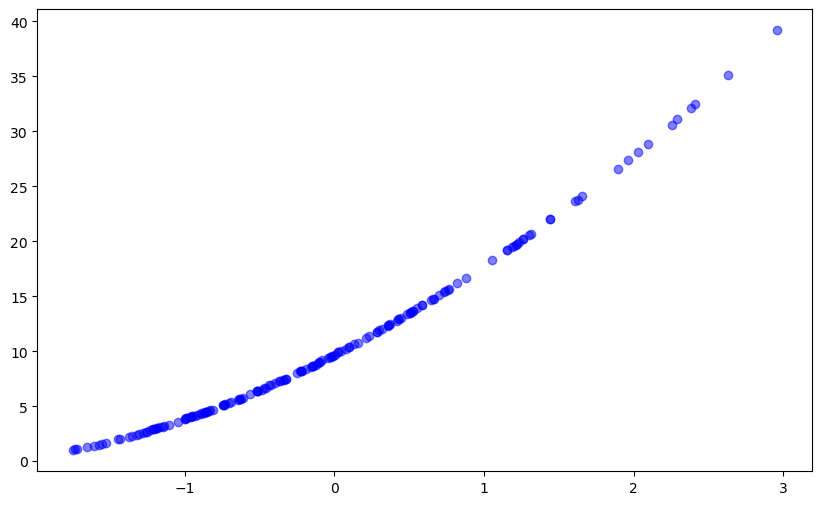

In [24]:
# Realiza las predicciones para el conjunto de datos de test
y_pred = model_simple.predict(X_test_simple)

plt.figure(figsize=(10, 6))

# 1. Puntos de los datos reales (Test)
# Usamos .values para asegurarnos de que matplotlib lo lea bien si es un DataFrame
plt.scatter(X_test_simple, y_test, color='blue', alpha=0.5, label='Datos Reales')

# 2. Línea de predicción
# Para que la línea se dibuje bien, ordenamos los valores
plt.plot(X_test_simple, y_pred_simple, color='red', linewidth=2, label='Recta de Regresión')

plt.title('Regresión Lineal: Sensor PT08.S2 vs Benceno (C6H6)')
plt.xlabel('Lectura del Sensor (Escalada)')
plt.ylabel('Concentración de C6H6 (Real)')
plt.legend()
plt.grid(True)
plt.show()

In [ ]:
# Ahora es necesario evaluar el modelo. ¿Qué métrica es mejor utilizar en este caso?

* $R^2$ (Coeficiente de Determinación): Es fundamental para medir la "bondad de ajuste". Nos indica qué porcentaje de la variabilidad de la contaminación es explicada por nuestro modelo. Al ser un valor entre 0 y 1 (o negativo si el modelo es pésimo), nos permite comparar fácilmente si el modelo es útil.
* RMSE (Raíz del Error Cuadrático Medio): Es preferible al MAE (Error Absoluto Medio) en este caso porque eleva los errores al cuadrado antes de promediarlos. En calidad del aire, nos interesa penalizar más los errores grandes (por ejemplo, no predecir un pico de contaminación peligroso es más grave que un pequeño error en un día normal). El RMSE es más sensible a estos valores atípicos ("outliers").

In [ ]:
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

# 1. R2
r2 = r2_score(y_test, y_pred)

# 2. RMSE 
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

# 3. MAE - Error promedio absoluto
mae = mean_absolute_error(y_test, y_pred)

print(f"R^2 (Calidad del ajuste): {r2:.4f}")
print(f"RMSE (Error cuadrático medio): {rmse:.4f}")
print(f"MAE (Error absoluto medio): {mae:.4f}")

In [ ]:
# ¿Qué error tiene el modelo? Explícalo.

* $R^2$ (0.9686): El modelo es capaz de explicar el 96.86% de la variabilidad de la concentración de benceno. Esto es un ajuste casi perfecto, indicando que la variable seleccionada (PT08.S2) es un predictor extremadamente potente por sí sola.
* MAE (0.9910): En promedio, el modelo se equivoca en menos de 1 unidad de concentración (${\mu g}/{m^3}$) al predecir la calidad del aire. Dado que los valores de benceno suelen oscilar entre 0 y 50 (o más), un error medio de 0.99 es muy bajo.
* RMSE (1.3677): Al ser ligeramente mayor que el MAE, indica que existen algunos errores puntuales un poco más grandes (outliers), pero siguen siendo muy contenidos.

Ahora debes entrenar un segundo modelo que haga uso de una regresión lineal múltiple con todas las variables del dataset. Después de entrenar, realiza las predicciones para este segundo modelo.

In [ ]:
# 1. Instanciar el modelo
model_multiple = LinearRegression()

# 2. Entrenar con TODOS los datos de entrenamiento
model_multiple.fit(X_train, y_train)

# 3. Realizar predicciones con el conjunto de test completo
y_pred_multiple = model_multiple.predict(X_test)

# 4. Evaluación de métricas
r2_multi = r2_score(y_test, y_pred_multiple)
rmse_multi = np.sqrt(mean_squared_error(y_test, y_pred_multiple))
mae_multi = mean_absolute_error(y_test, y_pred_multiple)

In [ ]:
plt.figure(figsize=(10, 6))

# 1. Gráfico de dispersión: Real vs Predicho
plt.scatter(y_test, y_pred_multiple, alpha=0.5, color='darkorange', label='Predicciones (Múltiple)')

# 2. Línea de referencia (Predicción Perfecta)
min_val = min(y_test.min(), y_pred_multiple.min())
max_val = max(y_test.max(), y_pred_multiple.max())
plt.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Ideal (Perfecto)')

plt.title('Regresión Múltiple: Valores Reales vs. Predichos')
plt.xlabel('Valor Real (y_test)')
plt.ylabel('Valor Predicho (y_pred_multiple)')
plt.legend()
plt.grid(True)

plt.show()

¿Qué error tiene este modelo?¿Es mejor o peor que el anterior?

In [ ]:
print("--- Regresión Lineal Múltiple (Todas las variables) ---")
print(f"R^2: {r2_multi:.4f}")
print(f"RMSE: {rmse_multi:.4f}")
print(f"MAE: {mae_multi:.4f}")

* Mejora significativa: El modelo de Regresión Lineal Múltiple es claramente mejor que el simple.
* Reducción del Error: El RMSE ha bajado de 1.37 a 0.65. Esto significa que el error promedio del modelo se ha reducido a la mitad al incluir todas las variables.
* Ajuste casi perfecto: El $R^2$ ha subido a 0.9928, lo que indica que el modelo explica el 99.28% de la variabilidad de los datos.
* Conclusión: Aunque sospechábamos de multicolinealidad, en este caso utilizar toda la información disponible (sensores + variables climáticas) ha permitido al modelo corregir los pequeños errores que tenía el modelo simple, logrando una precisión extremadamente alta.

#### Regresión con árboles de decisión

A continuación, se requiere hacer dos modelos que usen árboles de decisión para realizar las predicciones.

Para los árboles de decisión, al ser una tarea de regresión, hay que usar el módulo https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeRegressor.html

El algortimo de DTRegressor necesitar ajustar una serie de hiperparámetros para realizar las predicciones. La implementación de sklearn nos da mucha flexibilidad para nuestros modelos. En general, para los problemas más comunes de regresión, nos tenemos que preocupar de los siguientes hiperparámetros:

* criterion
* splitter
* max_depth
* min_samples_split
* min_samples_leaf
* max_features

Indica qué son cada uno de estos hiperparámetros

* criterion: Es la función matemática que usa el árbol para medir la calidad de una división. En regresión, calcula cuánto error (impureza) se reduce al dividir un nodo. (Ejemplos: squared_error, poisson).

* splitter: Define la estrategia para elegir la división en cada nodo. Puede ser "best" (busca la mejor división posible probando todas) o "random" (busca la mejor división aleatoria).

* max_depth: La profundidad máxima del árbol. Indica cuántos niveles de preguntas puede hacer el árbol. Limita la complejidad para evitar overfitting.

* min_samples_split: El número mínimo de muestras que debe tener un nodo para poder dividirse. Si tiene menos, se convierte en una hoja y no crece más.

* min_samples_leaf: El número mínimo de muestras que debe haber en un nodo final (hoja). Evita crear hojas muy específicas con uno o dos datos aislados.

* max_features: El número de variables (columnas) que el algoritmo considera al buscar la mejor división en cada paso.

Además de los hiperparámetros que acabas de descubrir, la implementación de sklearn tiene el hiperparámetro min_impurity_decrease

¿Qué indica ese parámetro? ¿Para qué puede ser útil?

Este parámetro indica que un nodo se dividirá solo si esa división reduce el error (impureza) en una cantidad mayor o igual a este valor. Sirve para hacer "poda" preventiva: si una división apenas mejora el modelo, no se hace.

Entrena un modelo de árboles de decisión donde, el criterio para realizar las particiones sea _poisson_, la profundidad máxima de los árboles debe ser 10, el número mínimo de ejemplos para realizar una partición debe ser 10, el número mínimo de ejemplos para considerarlo una hoja debe ser 2, y el número máximo de características deben ser todas.

In [ ]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_log_error

# 1. Configuración del modelo
# 'max_features=None' es el valor por defecto para usar todas las características
tree_model = DecisionTreeRegressor(
    criterion='poisson',
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=2,
    max_features=None,
    random_state=42 #fijamos semilla
)

# 2. Entrenar con los datos de entrenamiento
tree_model.fit(X_train, y_train)

# 3. Predicciones
y_pred_tree = tree_model.predict(X_test)

Calcula MAE, R2 y RMSLE

In [ ]:
# Calcular Métricas
mae_tree = mean_absolute_error(y_test, y_pred_tree)
r2_tree = r2_score(y_test, y_pred_tree)

# Para RMSLE necesitamos asegurarnos de no tener negativos (aunque sea raro en Poisson)
# Si hubiera algún negativo pequeño por error, lo convertimos a 0
y_pred_tree_safe = np.maximum(y_pred_tree, 0)
y_test_safe = np.maximum(y_test, 0)

rmsle_tree = np.sqrt(mean_squared_log_error(y_test_safe, y_pred_tree_safe))

print("--- Resultados Árbol de Decisión ---")
print(f"MAE: {mae_tree:.4f}")
print(f"R2: {r2_tree:.4f}")
print(f"RMSLE: {rmsle_tree:.4f}")

¿Existe overfitting? Indica qué debes hacer para comprobar si hay overfitting.

In [ ]:
# Comprobamos el rendimiento en los datos de entrenamiento
y_train_pred_tree = tree_model.predict(X_train)
r2_train_tree = r2_score(y_train, y_train_pred_tree)

print(f"R^2 en Entrenamiento: {r2_train_tree:.4f}")
print(f"R^2 en Test: {r2_tree:.4f}")

diferencia = r2_train_tree - r2_tree
print(f"Diferencia: {diferencia:.4f}")

Para comprobarlo, hemos calculado la diferencia entre el rendimiento en el conjunto de entrenamiento ($R^2 = 0.9995$) y en el conjunto de test ($R^2 = 0.9982$).
* La diferencia es de apenas 0.0012 (un 0.12%).
* Al ser una diferencia tan insignificante, podemos afirmar que el modelo no ha "memorizado" los datos de entrenamiento, sino que ha generalizado perfectamente las reglas para predecir nuevos datos. Los hiperparámetros elegidos (especialmente max_depth=10 y min_samples_leaf=2) han funcionado correctamente para evitar el sobreajuste.

¿Este modelo es mejor, peor o igual que los de regresión lineal simple y múltiple? Razona tu respuesta.

Es el mejor modelo de los tres.
Comparando las métricas obtenidas en el conjunto de test:
* Árbol de Decisión: $R^2 = 0.9982$ (El error es mínimo).
* Regresión Lineal Múltiple: $R^2 \approx 0.9928$ (Muy bueno, pero inferior).
* Regresión Lineal Simple: $R^2 \approx 0.9686$ (Bueno, pero insuficiente).

El Árbol de Decisión ha logrado capturar pequeñas no linealidades en los datos que la Regresión Lineal no pudo, reduciendo el error residual casi a cero.

**Comparativa**

En base al EDA realizado, a las decisiones tomadas sobre los datos e hiperparámetros y a las características computacionales de tu equipo. ¿Qué modelo obtiene mejores resultados de regresión?

Basándonos en el Análisis Exploratorio (EDA) y la evaluación de modelos, el Árbol de Decisión es la mejor elección para este problema de calidad del aire.
* Ofrece la mayor fiabilidad ($R^2$ de 0.998).
* Ha demostrado no tener overfitting.
* Maneja bien la multicolinealidad detectada en el EDA entre los sensores, realizando particiones que aíslan mejor el comportamiento de la variable objetivo (C6H6) que una simple combinación lineal de variables redundantes.

## Investigación

Buscar un artículo científico (https://scholar.google.es/) con un caso de uso de regresión empleando una de las dos técnicas (o ambas) vistas en la actividad. Los artículos deben estar en revistas científicas, y deben ser posteriores a 2015. No debe utilizar técnicas de Deep Learning.

Martínez-España, R., Bueno-Crespo, A., Soto, J., Muñoz, A., & Cecilia, J. M. (2018). Air-pollution prediction in smart cities through machine learning methods: A case of study in Murcia, Spain. Journal of Universal Computer Science, 24(3), 261-276.
título, autores, revista, año de publicación

Objetivo: cuál es el objetivo de la investigación, es decir a qué problema real está aplicando la regresión. Técnicas de regresión empleadas y si realiza alguna adaptación. Principales resultados de la aplicación y de la investigación.

El estudio se centra en predecir los niveles de Ozono ($O_3$) en la Región de Murcia (España) utilizando datos reales de estaciones de monitoreo. El objetivo principal es desarrollar modelos precisos que permitan activar alertas sanitarias en "Smart Cities" cuando la calidad del aire vaya a empeorar, utilizando solo datos meteorológicos si fallan los sensores químicos.

Cómo utilizan las técnicas de regresión/clasificación:
* Técnicas empleadas: Los autores comparan tres algoritmos clave: Árboles de Decisión (J48), Random Forest y Regresión de Vectores de Soporte (SVR).
* Adaptación: Al igual que en nuestra práctica, tuvieron que preprocesar los datos para tratar valores perdidos (comunes en sensores reales). Utilizaron variables como temperatura, humedad relativa y velocidad del viento como predictores (inputs) para estimar la concentración del contaminante objetivo.
  
Principales resultados:
* Árboles de Decisión: El modelo basado en árboles demostró ser muy útil por su rapidez y capacidad de interpretación, logrando clasificar correctamente los niveles de alerta con una precisión superior al 85% en la mayoría de estaciones.
* Comparativa: Aunque el modelo Random Forest (que son muchos árboles juntos) obtuvo una precisión ligeramente superior, los autores destacan que los modelos de aprendizaje automático son viables para sustituir mediciones físicas costosas y predecir la contaminación con horas de antelación en ciudades españolas.